# 01 — Khám phá dữ liệu Diginetica

Notebook này chỉ **đọc dữ liệu raw**, kiểm tra chất lượng và tạo bằng chứng cho quyết định tiền xử lý. Notebook **không chia train/validation/test**, không tạo cold item và không sửa dữ liệu nguồn.

Các câu hỏi chính:

1. Ba file raw có đúng schema và liên kết đầy đủ không?
2. Thứ tự thời gian trong session có đáng tin cậy không?
3. Session dài bao nhiêu và click lặp phổ biến tới mức nào?
4. Dữ liệu có phân bố long-tail đủ rõ để nghiên cứu popularity bias không?
5. Category có phản ánh cấu trúc hành vi trong session không?
6. Các session qua nửa đêm và timestamp trùng cần xử lý thế nào?
7. Pipeline lọc chuẩn làm thay đổi bao nhiêu dữ liệu?
8. Ngưỡng hỗ trợ item 1/2/3/5/10 đánh đổi long-tail ra sao?

> Popularity trong notebook này chỉ có tính mô tả. Popularity dùng cho thí nghiệm chính phải được tính lại **chỉ từ tập train** trong notebook `02_preprocessing.ipynb`.

## 1. Thiết lập môi trường và đường dẫn

In [1]:
from pathlib import Path
import hashlib
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "BTL-K03-tong-quan-de-tai.md").exists():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục gốc của dự án.")


PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "diginetica"
TABLE_DIR = PROJECT_ROOT / "results" / "tables"
FIGURE_DIR = PROJECT_ROOT / "results" / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Python      :", sys.executable)
print("Project root:", PROJECT_ROOT)
print("Raw data    :", RAW_DIR)

Python      : D:\DL\.venv\Scripts\python.exe
Project root: D:\DA-3
Raw data    : D:\DA-3\data\raw\diginetica


## 2. Đọc ba file raw và lập manifest

Manifest lưu kích thước và SHA-256 để có thể xác nhận đúng phiên bản dữ liệu khi tái lập thí nghiệm.

In [2]:
RAW_FILES = {
    "views": RAW_DIR / "train-item-views.csv",
    "categories": RAW_DIR / "product-categories.csv",
    "products": RAW_DIR / "products.csv",
}

missing_files = [str(path) for path in RAW_FILES.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Thiếu file raw: {missing_files}")


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


views = pd.read_csv(RAW_FILES["views"], sep=";", na_values=["NA"])
categories = pd.read_csv(RAW_FILES["categories"], sep=";")
products = pd.read_csv(RAW_FILES["products"], sep=";")
frames = {"views": views, "categories": categories, "products": products}

manifest = pd.DataFrame([
    {
        "logical_name": name,
        "file_name": path.name,
        "size_bytes": path.stat().st_size,
        "rows": len(frames[name]),
        "sha256": sha256_file(path),
    }
    for name, path in RAW_FILES.items()
])
manifest.to_csv(TABLE_DIR / "eda_raw_file_manifest.csv", index=False)

display(manifest)
display(views.head())
display(categories.head())
display(products.head())

,logical_name,file_name,size_bytes,rows,sha256
0,views,train-item-views.csv,43899457,1235380,5a27dbd1a7d47867ef64aff378dbed971131f0f6fcd86f...
1,categories,product-categories.csv,2163623,184047,e5b7d2cda115f0ec3f5d5d571d247147a23a5ec1bf6249...
2,products,products.csv,7520465,184047,cfe9d17ebd07dba16879a04fc556f223f758001f99a2e3...


,sessionId,userId,itemId,timeframe,eventdate
0,1,NaN,81766,526309,2016-05-09
1,1,NaN,31331,1031018,2016-05-09
2,1,NaN,32118,243569,2016-05-09
3,1,NaN,9654,75848,2016-05-09
4,1,NaN,32627,1112408,2016-05-09


,itemId,categoryId
0,139578,1096
1,417975,1096
2,291805,1096
3,396921,1096
4,159257,1096


,itemId,pricelog2,product.name.tokens
0,1,10,"4875,776,56689,18212,18212,4896"
1,69585,6,"7583,18117,41805,41805,2371"
2,90939,6,"604,18117,41805,41805,2371"
3,69586,0,"2936,18117,41805,41805,2371"
4,30029,7,"4668,41805,41805,56652"


## 3. Schema, missing value, duplicate và liên kết giữa các file

`userId` không phải đầu vào chính của bài toán session-based. Notebook chỉ ghi nhận mức thiếu và không điền giá trị cho cột này.

In [3]:
expected_columns = {
    "views": ["sessionId", "userId", "itemId", "timeframe", "eventdate"],
    "categories": ["itemId", "categoryId"],
    "products": ["itemId", "pricelog2", "product.name.tokens"],
}

schema_rows = []
for frame_name, frame in frames.items():
    for column in frame.columns:
        schema_rows.append({
            "table": frame_name,
            "column": column,
            "dtype": str(frame[column].dtype),
            "missing_count": int(frame[column].isna().sum()),
            "missing_pct": float(frame[column].isna().mean() * 100),
            "n_unique": int(frame[column].nunique(dropna=True)),
        })
schema_summary = pd.DataFrame(schema_rows)

parsed_eventdate = pd.to_datetime(views["eventdate"], errors="coerce")
view_items = pd.Index(views["itemId"].unique())
category_items = pd.Index(categories["itemId"].unique())
product_items = pd.Index(products["itemId"].unique())

quality_checks = pd.DataFrame([
    ("views_schema_exact", list(views.columns) == expected_columns["views"]),
    ("categories_schema_exact", list(categories.columns) == expected_columns["categories"]),
    ("products_schema_exact", list(products.columns) == expected_columns["products"]),
    ("views_exact_duplicate_rows", int(views.duplicated().sum())),
    ("categories_exact_duplicate_rows", int(categories.duplicated().sum())),
    ("products_exact_duplicate_rows", int(products.duplicated().sum())),
    ("duplicate_view_event_keys", int(views.duplicated(["sessionId", "itemId", "timeframe", "eventdate"]).sum())),
    ("duplicate_category_item_ids", int(categories["itemId"].duplicated().sum())),
    ("duplicate_product_item_ids", int(products["itemId"].duplicated().sum())),
    ("eventdate_parse_failures", int(parsed_eventdate.isna().sum())),
    ("negative_timeframe_rows", int((views["timeframe"] < 0).sum())),
    ("view_items_without_category", int((~view_items.isin(category_items)).sum())),
    ("view_items_without_product", int((~view_items.isin(product_items)).sum())),
    ("metadata_items_never_viewed", int((~product_items.isin(view_items)).sum())),
], columns=["check", "value"])

schema_summary.to_csv(TABLE_DIR / "eda_schema_summary.csv", index=False)
quality_checks.to_csv(TABLE_DIR / "eda_data_quality_summary.csv", index=False)
display(schema_summary)
display(quality_checks)

,table,column,dtype,missing_count,missing_pct,n_unique
0,views,sessionId,int64,0,0.0000,310324
1,views,userId,float64,862389,69.8076,87934
2,views,itemId,int64,0,0.0000,122993
3,views,timeframe,int64,0,0.0000,644845
4,views,eventdate,object,0,0.0000,152
5,categories,itemId,int64,0,0.0000,184047
6,categories,categoryId,int64,0,0.0000,1217
7,products,itemId,int64,0,0.0000,184047
8,products,pricelog2,int64,0,0.0000,13
9,products,product.name.tokens,object,0,0.0000,182392


,check,value
0,views_schema_exact,True
1,categories_schema_exact,True
2,products_schema_exact,True
3,views_exact_duplicate_rows,0
4,categories_exact_duplicate_rows,0
5,products_exact_duplicate_rows,0
6,duplicate_view_event_keys,0
7,duplicate_category_item_ids,0
8,duplicate_product_item_ids,0
9,eventdate_parse_failures,0


## 4. Chuẩn hóa thứ tự sự kiện và trục thời gian

`timeframe` là số mili giây tương đối kể từ đầu session, vì vậy đây là khóa chính để sắp thứ tự event bên trong session. `eventdate` được giữ làm ngày lịch cho thống kê và chia tập theo thời gian. `_row_order` phá hòa ổn định khi hai event có cùng `timeframe`.

Không cộng `eventdate + timeframe` để đo duration: 260 session đi qua nửa đêm sẽ bị diễn giải sai thành dài hơn 24 giờ.


In [4]:
events = views.copy()
events["_row_order"] = np.arange(len(events), dtype=np.int64)
events["eventdate"] = parsed_eventdate
events["sequence_time_ms"] = events["timeframe"].astype(np.int64)

raw_time_diff = events.groupby("sessionId", sort=False)["sequence_time_ms"].diff()
sessions_out_of_order = int(
    events.loc[raw_time_diff.lt(0), "sessionId"].nunique()
)
sessions_multiple_dates = int(
    events.groupby("sessionId")["eventdate"].nunique().gt(1).sum()
)
duplicate_session_timeframe = int(
    events.duplicated(["sessionId", "sequence_time_ms"]).sum()
)

time_quality = pd.DataFrame([
    ("date_min", events["eventdate"].min()),
    ("date_max", events["eventdate"].max()),
    ("number_of_dates", int(events["eventdate"].nunique())),
    ("timeframe_min_ms", int(events["sequence_time_ms"].min())),
    ("timeframe_max_ms", int(events["sequence_time_ms"].max())),
    ("sessions_out_of_raw_order", sessions_out_of_order),
    ("sessions_out_of_raw_order_pct", sessions_out_of_order / events["sessionId"].nunique() * 100),
    ("sessions_spanning_multiple_dates", sessions_multiple_dates),
    ("duplicate_session_timeframe_extra_rows", duplicate_session_timeframe),
], columns=["check", "value"])

events = events.sort_values(
    ["sessionId", "sequence_time_ms", "_row_order"], kind="mergesort"
).reset_index(drop=True)

time_quality.to_csv(TABLE_DIR / "eda_time_quality_summary.csv", index=False)
display(time_quality)


,check,value
0,date_min,2016-01-01 00:00:00
1,date_max,2016-06-01 00:00:00
2,number_of_dates,152
3,timeframe_min_ms,12
4,timeframe_max_ms,1199992
5,sessions_out_of_raw_order,180643
6,sessions_out_of_raw_order_pct,58.2111
7,sessions_spanning_multiple_dates,260
8,duplicate_session_timeframe_extra_rows,4


## 5. Cấu trúc session và hành vi click lặp

,quantile,session_length,unique_items,unique_categories,duration_seconds
0,0.0000,1.0000,1.0000,1.0000,0.0000
1,0.2500,1.0000,1.0000,1.0000,0.0000
2,0.5000,3.0000,2.0000,1.0000,171.7930
3,0.7500,5.0000,4.0000,1.0000,555.8732
4,0.9000,9.0000,7.0000,2.0000,947.9509
5,0.9500,12.0000,10.0000,3.0000,"1,065.9102"
6,0.9900,19.0000,16.0000,5.0000,"1,152.7241"
7,1.0000,87.0000,77.0000,18.0000,"1,196.7530"


,length_group,sessions,events,session_pct,event_pct
0,1,90694,90694,29.2256,7.3414
1,2–5,148480,460235,47.8468,37.2545
2,6–10,50708,379061,16.3403,30.6838
3,>10,20442,305390,6.5873,24.7203


,metric,value
0,sessions_with_repeated_items,"86,439.0000"
1,sessions_with_repeated_items_pct,27.8544
2,all_repeat_events,"168,313.0000"
3,all_repeat_events_pct,13.6244
4,consecutive_repeat_events,"72,265.0000"
5,non_consecutive_repeat_events,"96,048.0000"


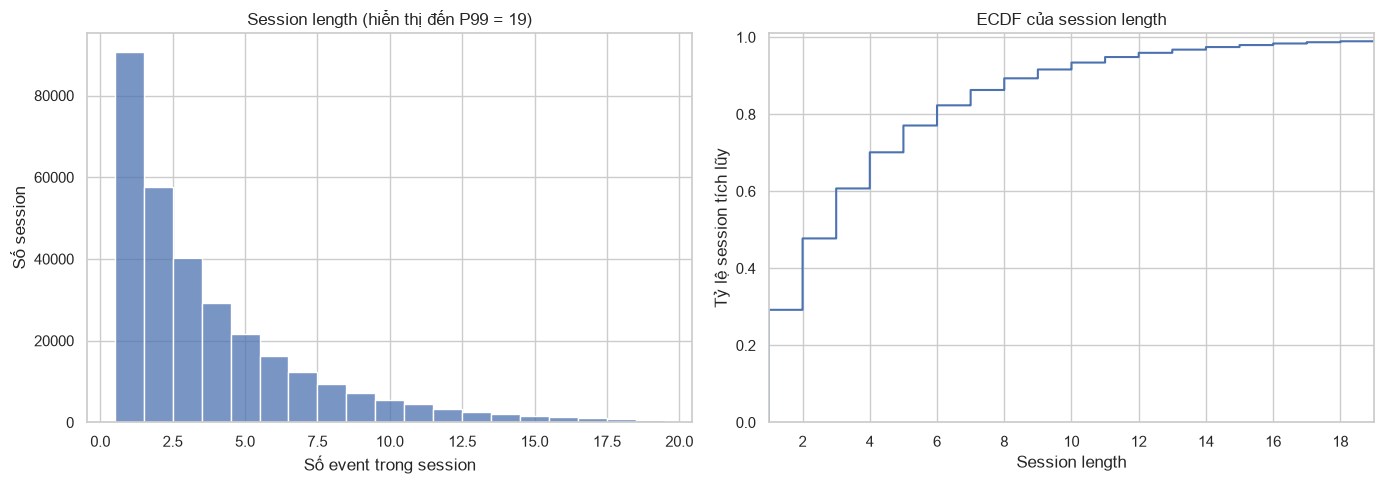

In [5]:
events_with_category = events.merge(
    categories, on="itemId", how="left", validate="many_to_one"
)
session_group = events_with_category.groupby("sessionId", sort=False)
session_stats = session_group.agg(
    session_length=("itemId", "size"),
    unique_items=("itemId", "nunique"),
    unique_categories=("categoryId", "nunique"),
    start_date=("eventdate", "min"),
    end_date=("eventdate", "max"),
    start_timeframe_ms=("sequence_time_ms", "min"),
    end_timeframe_ms=("sequence_time_ms", "max"),
).reset_index()
session_stats["duration_seconds"] = (
    session_stats["end_timeframe_ms"] - session_stats["start_timeframe_ms"]
) / 1000
session_stats["repeat_events"] = (
    session_stats["session_length"] - session_stats["unique_items"]
)
session_stats["length_group"] = pd.cut(
    session_stats["session_length"],
    bins=[0, 1, 5, 10, np.inf],
    labels=["1", "2–5", "6–10", ">10"],
)

same_session = events_with_category["sessionId"].eq(events_with_category["sessionId"].shift())
same_item = events_with_category["itemId"].eq(events_with_category["itemId"].shift())
consecutive_repeat_events = int((same_session & same_item).sum())
all_repeat_events = int(session_stats["repeat_events"].sum())

session_quantiles = session_stats[
    ["session_length", "unique_items", "unique_categories", "duration_seconds"]
].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1]).rename_axis("quantile").reset_index()

session_group_summary = session_stats.groupby("length_group", observed=False).agg(
    sessions=("sessionId", "size"),
    events=("session_length", "sum"),
).reset_index()
session_group_summary["session_pct"] = session_group_summary["sessions"] / len(session_stats) * 100
session_group_summary["event_pct"] = session_group_summary["events"] / len(events) * 100

repeat_summary = pd.DataFrame([
    ("sessions_with_repeated_items", int(session_stats["repeat_events"].gt(0).sum())),
    ("sessions_with_repeated_items_pct", float(session_stats["repeat_events"].gt(0).mean() * 100)),
    ("all_repeat_events", all_repeat_events),
    ("all_repeat_events_pct", all_repeat_events / len(events) * 100),
    ("consecutive_repeat_events", consecutive_repeat_events),
    ("non_consecutive_repeat_events", all_repeat_events - consecutive_repeat_events),
], columns=["metric", "value"])

session_quantiles.to_csv(TABLE_DIR / "eda_session_quantiles.csv", index=False)
session_group_summary.to_csv(TABLE_DIR / "eda_session_length_groups.csv", index=False)
repeat_summary.to_csv(TABLE_DIR / "eda_repeat_click_summary.csv", index=False)
display(session_quantiles)
display(session_group_summary)
display(repeat_summary)

plot_limit = int(np.ceil(session_stats["session_length"].quantile(0.99)))
sorted_lengths = np.sort(session_stats["session_length"].to_numpy())
ecdf = np.arange(1, len(sorted_lengths) + 1) / len(sorted_lengths)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(
    session_stats.loc[session_stats["session_length"] <= plot_limit, "session_length"],
    discrete=True,
    ax=axes[0],
)
axes[0].set(
    title=f"Session length (hiển thị đến P99 = {plot_limit})",
    xlabel="Số event trong session",
    ylabel="Số session",
)
axes[1].step(sorted_lengths, ecdf, where="post")
axes[1].set(
    xlim=(1, plot_limit),
    ylim=(0, 1.01),
    title="ECDF của session length",
    xlabel="Session length",
    ylabel="Tỷ lệ session tích lũy",
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda_session_length_histogram_ecdf.png", dpi=180, bbox_inches="tight")
plt.show()

### 5.1. Audit session qua ngày và thời gian bất thường

Phần này phân biệt session thực sự kéo dài bất thường với session ngắn đi qua nửa đêm. Quy tắc được kiểm tra từ dữ liệu: số ngày, độ liên tiếp của ngày, tính đơn điệu của `eventdate` khi đã sắp theo `timeframe`, duration đúng theo `timeframe`, và các giá trị thời gian trùng.


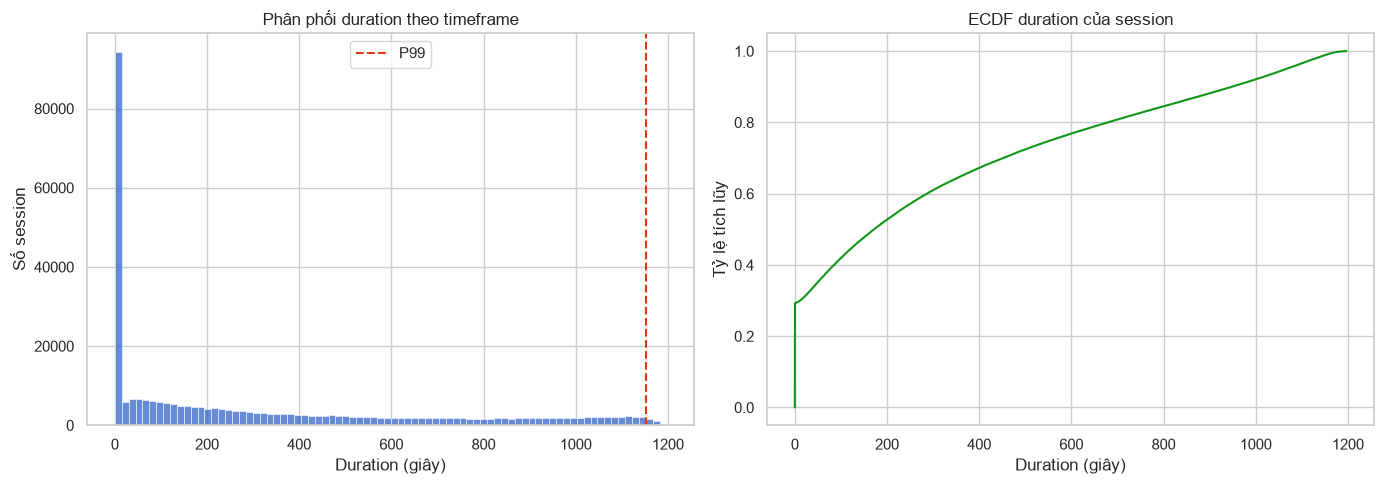

,check,value
0,sessions_total,310324
1,sessions_spanning_multiple_dates,260
2,multi_day_all_exactly_two_consecutive_dates,True
3,multi_day_with_date_reversal_after_timeframe_sort,0
4,duplicate_session_timeframe_extra_rows,4
5,duplicate_session_timeframe_groups,4
6,duration_p99_seconds,"1,152.7241"
7,duration_p999_seconds,"1,182.0151"
8,duration_max_seconds,"1,196.7530"
9,sessions_duration_ge_30_minutes,0


,sessionId,first_eventdate,last_eventdate,date_count,events,unique_items,timeframe_min_ms,timeframe_max_ms,date_span_days,duration_seconds,is_multi_day,is_duration_above_p999,has_duplicate_timeframe,has_date_reversal_after_timeframe_sort,dates_are_consecutive
61213,91034,2016-05-09,2016-05-10,2,9,7,12576,1195019,1,"1,182.4430",True,True,False,False,True
105908,163410,2016-05-27,2016-05-28,2,7,7,13592,1191438,1,"1,177.8460",True,False,False,False,True
163560,264880,2016-02-16,2016-02-17,2,16,15,23668,1197031,1,"1,173.3630",True,False,False,False,True
456,629,2016-03-20,2016-03-21,2,17,6,13879,1184885,1,"1,171.0060",True,False,False,False,True
10953,16238,2016-02-29,2016-03-01,2,4,4,16653,1185501,1,"1,168.8480",True,False,False,False,True
101192,155413,2016-04-30,2016-05-01,2,26,25,20380,1188237,1,"1,167.8570",True,False,False,False,True
58570,86927,2016-03-28,2016-03-29,2,4,4,17385,1184400,1,"1,167.0150",True,False,False,False,True
41238,60123,2016-05-29,2016-05-30,2,13,13,34381,1192908,1,"1,158.5270",True,False,False,False,True
214531,364985,2016-04-16,2016-04-17,2,6,5,29326,1187137,1,"1,157.8110",True,False,False,False,True
201934,339141,2016-03-17,2016-03-18,2,4,3,38764,1194796,1,"1,156.0320",True,False,False,False,True


Khuyến nghị EDA: giữ nguyên 260 session qua nửa đêm; sắp event theo timeframe và dùng _row_order để phá hòa.


In [6]:
session_calendar = events.groupby("sessionId", sort=False).agg(
    first_eventdate=("eventdate", "min"),
    last_eventdate=("eventdate", "max"),
    date_count=("eventdate", "nunique"),
    events=("itemId", "size"),
    unique_items=("itemId", "nunique"),
    timeframe_min_ms=("sequence_time_ms", "min"),
    timeframe_max_ms=("sequence_time_ms", "max"),
).reset_index()
session_calendar["date_span_days"] = (
    session_calendar["last_eventdate"] - session_calendar["first_eventdate"]
).dt.days
session_calendar["duration_seconds"] = (
    session_calendar["timeframe_max_ms"] - session_calendar["timeframe_min_ms"]
) / 1000

ordered_date_diff = events.groupby("sessionId", sort=False)["eventdate"].diff()
sessions_with_date_reversal = pd.Index(
    events.loc[ordered_date_diff.lt(pd.Timedelta(0)), "sessionId"].unique()
)

multi_day_ids = pd.Index(
    session_calendar.loc[session_calendar["date_count"] > 1, "sessionId"]
)
duplicate_timeframe_mask = events.duplicated(
    ["sessionId", "sequence_time_ms"], keep=False
)
duplicate_timeframes = events.loc[
    duplicate_timeframe_mask,
    ["sessionId", "itemId", "eventdate", "timeframe", "_row_order"],
].sort_values(["sessionId", "timeframe", "_row_order"])
duplicate_timeframe_ids = pd.Index(duplicate_timeframes["sessionId"].unique())

duration_p999 = float(session_calendar["duration_seconds"].quantile(0.999))
long_duration_ids = pd.Index(
    session_calendar.loc[
        session_calendar["duration_seconds"] > duration_p999, "sessionId"
    ]
)
anomaly_ids = multi_day_ids.union(duplicate_timeframe_ids).union(long_duration_ids)

session_time_anomalies = session_calendar[
    session_calendar["sessionId"].isin(anomaly_ids)
].copy()
session_time_anomalies["is_multi_day"] = session_time_anomalies["sessionId"].isin(multi_day_ids)
session_time_anomalies["is_duration_above_p999"] = session_time_anomalies["sessionId"].isin(long_duration_ids)
session_time_anomalies["has_duplicate_timeframe"] = session_time_anomalies["sessionId"].isin(duplicate_timeframe_ids)
session_time_anomalies["has_date_reversal_after_timeframe_sort"] = session_time_anomalies["sessionId"].isin(sessions_with_date_reversal)
session_time_anomalies["dates_are_consecutive"] = (
    session_time_anomalies["date_span_days"]
    == session_time_anomalies["date_count"] - 1
)
session_time_anomalies = session_time_anomalies.sort_values(
    ["is_multi_day", "duration_seconds"], ascending=[False, False]
)

multi_day_detail = session_time_anomalies[session_time_anomalies["is_multi_day"]]
session_time_audit_summary = pd.DataFrame([
    ("sessions_total", len(session_calendar)),
    ("sessions_spanning_multiple_dates", len(multi_day_ids)),
    ("multi_day_all_exactly_two_consecutive_dates", bool(
        multi_day_detail["date_count"].eq(2).all()
        and multi_day_detail["dates_are_consecutive"].all()
    )),
    ("multi_day_with_date_reversal_after_timeframe_sort", int(
        multi_day_detail["has_date_reversal_after_timeframe_sort"].sum()
    )),
    ("duplicate_session_timeframe_extra_rows", duplicate_session_timeframe),
    ("duplicate_session_timeframe_groups", int(
        duplicate_timeframes.groupby(["sessionId", "timeframe"]).ngroups
    )),
    ("duration_p99_seconds", float(session_calendar["duration_seconds"].quantile(0.99))),
    ("duration_p999_seconds", duration_p999),
    ("duration_max_seconds", float(session_calendar["duration_seconds"].max())),
    ("sessions_duration_ge_30_minutes", int(
        session_calendar["duration_seconds"].ge(30 * 60).sum()
    )),
], columns=["check", "value"])

session_time_audit_summary.to_csv(
    TABLE_DIR / "eda_session_time_audit_summary.csv", index=False
)
session_time_anomalies.to_csv(
    TABLE_DIR / "eda_session_time_anomalies.csv", index=False
)
duplicate_timeframes.to_csv(
    TABLE_DIR / "eda_duplicate_timeframes.csv", index=False
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(
    session_calendar["duration_seconds"], bins=80, ax=axes[0], color="#3366cc"
)
axes[0].axvline(
    session_calendar["duration_seconds"].quantile(0.99),
    color="#dc3912", linestyle="--", label="P99",
)
axes[0].set(
    title="Phân phối duration theo timeframe",
    xlabel="Duration (giây)", ylabel="Số session",
)
axes[0].legend()

duration_sorted = np.sort(session_calendar["duration_seconds"].to_numpy())
ecdf = np.arange(1, len(duration_sorted) + 1) / len(duration_sorted)
axes[1].plot(duration_sorted, ecdf, color="#109618")
axes[1].set(
    title="ECDF duration của session",
    xlabel="Duration (giây)", ylabel="Tỷ lệ tích lũy",
)
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "eda_session_time_anomalies.png", dpi=180, bbox_inches="tight"
)
plt.show()

display(session_time_audit_summary)
display(session_time_anomalies.head(15))
print(
    "Khuyến nghị EDA: giữ nguyên 260 session qua nửa đêm; "
    "sắp event theo timeframe và dùng _row_order để phá hòa."
)


## 6. Biến động theo thời gian và vòng đời item

Spearman(item frequency, item age) = 0.5037


,count,mean,std,min,25%,50%,75%,max
interactions,152.0000,"8,127.5000","5,334.9714",2.0000,"4,826.5000","9,591.0000","12,419.7500","17,320.0000"
sessions,152.0000,"2,043.3158","1,325.6199",2.0000,"1,265.0000","2,394.0000","3,129.5000","4,338.0000"
active_items,152.0000,"5,217.8026","3,232.6378",2.0000,"3,559.7500","6,287.0000","7,850.0000","10,143.0000"
new_items,152.0000,809.1645,642.1670,0.0000,411.2500,747.0000,"1,039.7500","3,587.0000"


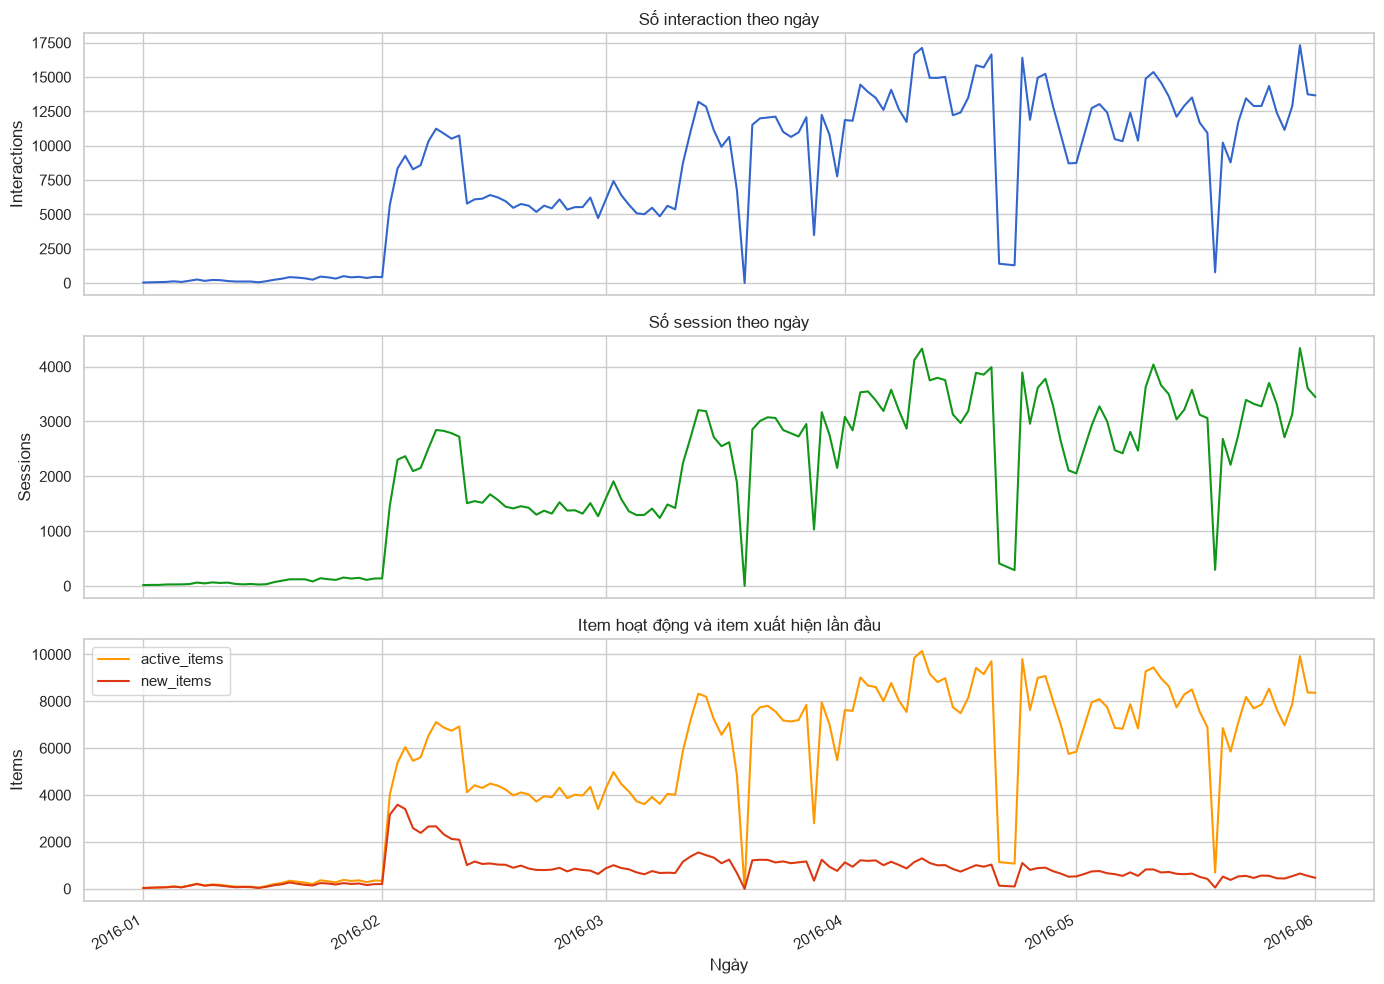

In [7]:
daily = events.groupby("eventdate").agg(
    interactions=("itemId", "size"),
    sessions=("sessionId", "nunique"),
    active_items=("itemId", "nunique"),
).sort_index()

item_lifecycle = events.groupby("itemId").agg(
    first_seen=("eventdate", "min"),
    last_seen=("eventdate", "max"),
    interaction_frequency=("itemId", "size"),
)
item_lifecycle["active_span_days"] = (
    item_lifecycle["last_seen"] - item_lifecycle["first_seen"]
).dt.days + 1
item_lifecycle["age_at_data_end_days"] = (
    events["eventdate"].max() - item_lifecycle["first_seen"]
).dt.days + 1
daily["new_items"] = item_lifecycle.groupby("first_seen").size().reindex(daily.index, fill_value=0)
age_frequency_spearman = spearmanr(
    item_lifecycle["interaction_frequency"],
    item_lifecycle["age_at_data_end_days"],
).statistic

daily.reset_index().to_csv(TABLE_DIR / "eda_daily_activity.csv", index=False)
item_lifecycle.reset_index().to_csv(TABLE_DIR / "eda_item_lifecycle_raw.csv", index=False)
print(f"Spearman(item frequency, item age) = {age_frequency_spearman:.4f}")
display(daily.describe().T)

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
daily["interactions"].plot(ax=axes[0], color="#3366cc")
axes[0].set(title="Số interaction theo ngày", ylabel="Interactions")
daily["sessions"].plot(ax=axes[1], color="#109618")
axes[1].set(title="Số session theo ngày", ylabel="Sessions")
daily[["active_items", "new_items"]].plot(ax=axes[2], color=["#ff9900", "#dc3912"])
axes[2].set(
    title="Item hoạt động và item xuất hiện lần đầu",
    xlabel="Ngày",
    ylabel="Items",
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda_daily_activity_and_new_items.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Item popularity và cấu trúc long tail

Phần này đo trên raw để mô tả dataset. Trong thí nghiệm chính, mọi frequency và popularity group phải được tính lại chỉ từ train.

Input-data Gini = 0.7260
Spearman(interaction frequency, session frequency) = 0.9812


,quantile,interaction_frequency,session_frequency
0,0.0000,1.0000,1.0000
1,0.2500,1.0000,1.0000
2,0.5000,3.0000,2.0000
3,0.7500,8.0000,7.0000
4,0.9000,22.0000,19.0000
5,0.9500,41.0000,35.0000
6,0.9900,121.0000,102.0000
7,1.0000,"1,270.0000","1,030.0000"


,top_item_pct,number_of_items,interaction_share_pct
0,1,1230,21.6453
1,5,6150,47.7693
2,10,12300,62.5322
3,20,24599,77.5441


,frequency_band,items,interactions,item_share_pct,interaction_share_pct
0,1,42060,42060,34.1971,3.4046
1,2–4,36404,98269,29.5984,7.9546
2,5,5335,26675,4.3376,2.1593
3,6–10,14906,113522,12.1194,9.1892
4,11–20,11067,162707,8.9981,13.1706
5,21–50,8551,269113,6.9524,21.7838
6,51–100,2997,207124,2.4367,16.7660
7,>100,1673,315910,1.3602,25.5719


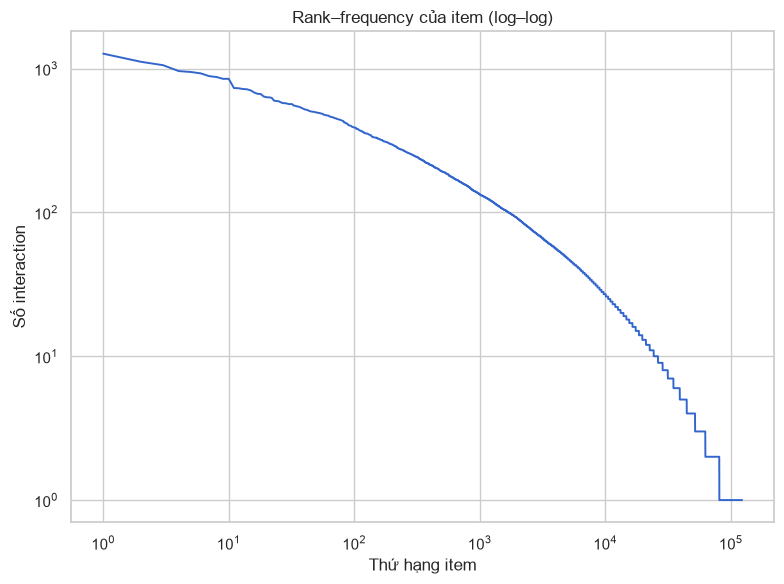

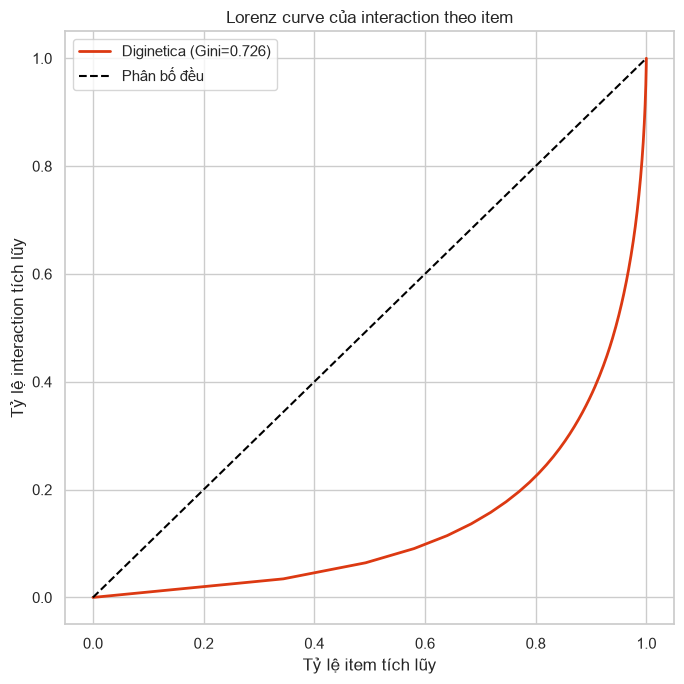

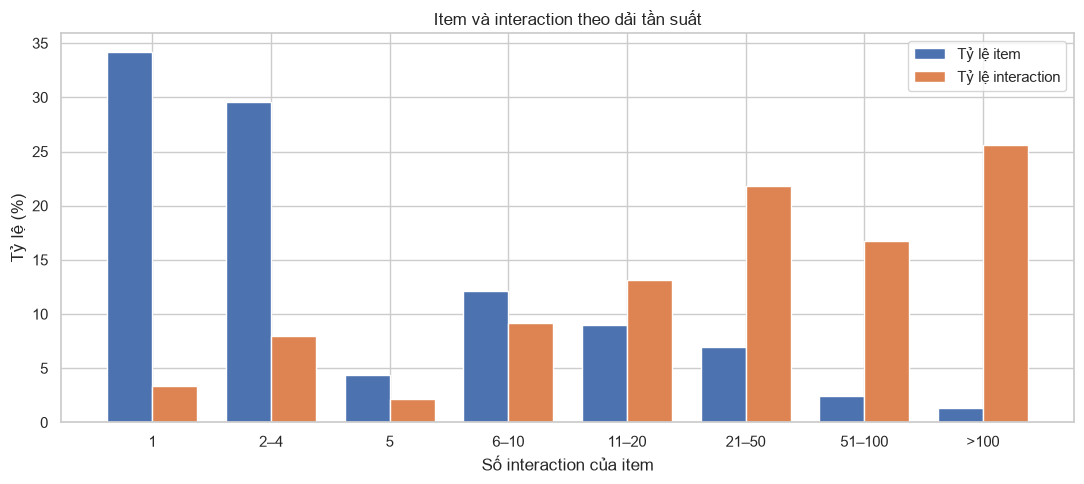

In [8]:
def gini_coefficient(values) -> float:
    array = np.asarray(values, dtype=np.float64)
    array = array[np.isfinite(array)]
    if len(array) == 0 or array.sum() == 0:
        return np.nan
    array = np.sort(np.clip(array, 0, None))
    n = len(array)
    return float(
        (2 * np.dot(np.arange(1, n + 1), array) / (n * array.sum()))
        - (n + 1) / n
    )


interaction_frequency = events["itemId"].value_counts().rename("interaction_frequency")
session_frequency = (
    events.drop_duplicates(["sessionId", "itemId"])["itemId"]
    .value_counts()
    .rename("session_frequency")
)
item_popularity = pd.concat(
    [interaction_frequency, session_frequency], axis=1
).fillna(0).astype(int)
frequency_spearman = spearmanr(
    item_popularity["interaction_frequency"],
    item_popularity["session_frequency"],
).statistic
input_gini = gini_coefficient(item_popularity["interaction_frequency"])

popularity_quantiles = item_popularity.quantile(
    [0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1]
).rename_axis("quantile").reset_index()

sorted_frequency = interaction_frequency.sort_values(ascending=False)
concentration_rows = []
for percentage in [1, 5, 10, 20]:
    item_count = max(1, int(np.ceil(len(sorted_frequency) * percentage / 100)))
    concentration_rows.append({
        "top_item_pct": percentage,
        "number_of_items": item_count,
        "interaction_share_pct": (
            sorted_frequency.iloc[:item_count].sum() / sorted_frequency.sum() * 100
        ),
    })
popularity_concentration = pd.DataFrame(concentration_rows)

frequency_bins = [0, 1, 4, 5, 10, 20, 50, 100, np.inf]
frequency_labels = ["1", "2–4", "5", "6–10", "11–20", "21–50", "51–100", ">100"]
item_popularity["frequency_band"] = pd.cut(
    item_popularity["interaction_frequency"],
    bins=frequency_bins,
    labels=frequency_labels,
    include_lowest=True,
)
frequency_band_summary = item_popularity.groupby(
    "frequency_band", observed=False
).agg(
    items=("interaction_frequency", "size"),
    interactions=("interaction_frequency", "sum"),
).reset_index()
frequency_band_summary["item_share_pct"] = (
    frequency_band_summary["items"] / frequency_band_summary["items"].sum() * 100
)
frequency_band_summary["interaction_share_pct"] = (
    frequency_band_summary["interactions"]
    / frequency_band_summary["interactions"].sum()
    * 100
)

item_popularity.reset_index(names="itemId").to_csv(
    TABLE_DIR / "eda_item_popularity_raw.csv", index=False
)
popularity_quantiles.to_csv(TABLE_DIR / "eda_popularity_quantiles.csv", index=False)
popularity_concentration.to_csv(TABLE_DIR / "eda_popularity_concentration.csv", index=False)
frequency_band_summary.to_csv(TABLE_DIR / "eda_frequency_bands.csv", index=False)

print(f"Input-data Gini = {input_gini:.4f}")
print(f"Spearman(interaction frequency, session frequency) = {frequency_spearman:.4f}")
display(popularity_quantiles)
display(popularity_concentration)
display(frequency_band_summary)

rank = np.arange(1, len(sorted_frequency) + 1)
fig, ax = plt.subplots(figsize=(8, 6))
ax.loglog(rank, sorted_frequency.to_numpy(), color="#3366cc", linewidth=1.4)
ax.set(
    title="Rank–frequency của item (log–log)",
    xlabel="Thứ hạng item",
    ylabel="Số interaction",
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda_item_rank_frequency_loglog.png", dpi=180, bbox_inches="tight")
plt.show()

ascending_frequency = np.sort(interaction_frequency.to_numpy(dtype=float))
lorenz_y = np.insert(np.cumsum(ascending_frequency) / ascending_frequency.sum(), 0, 0)
lorenz_x = np.linspace(0, 1, len(lorenz_y))
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(
    lorenz_x,
    lorenz_y,
    label=f"Diginetica (Gini={input_gini:.3f})",
    color="#dc3912",
    linewidth=2,
)
ax.plot([0, 1], [0, 1], linestyle="--", color="black", label="Phân bố đều")
ax.set(
    title="Lorenz curve của interaction theo item",
    xlabel="Tỷ lệ item tích lũy",
    ylabel="Tỷ lệ interaction tích lũy",
)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda_interaction_lorenz_curve.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(frequency_band_summary))
width = 0.38
ax.bar(
    x - width / 2,
    frequency_band_summary["item_share_pct"],
    width,
    label="Tỷ lệ item",
)
ax.bar(
    x + width / 2,
    frequency_band_summary["interaction_share_pct"],
    width,
    label="Tỷ lệ interaction",
)
ax.set_xticks(x, frequency_band_summary["frequency_band"].astype(str))
ax.set(
    title="Item và interaction theo dải tần suất",
    xlabel="Số interaction của item",
    ylabel="Tỷ lệ (%)",
)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "eda_items_and_interactions_by_frequency_band.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## 8. Category và cấu trúc chuyển tiếp trong session

So sánh chuyển tiếp cùng category với baseline độc lập giúp xác định category có thực sự phản ánh cấu trúc hành vi hay không.

,count,mean,std,min,25%,50%,75%,max
catalog_items,"1,217.0000",151.2301,283.6320,1.0000,10.0000,48.0000,187.0000,"3,851.0000"
active_items,"1,217.0000",101.0624,219.1051,0.0000,7.0000,30.0000,97.0000,"2,771.0000"
interactions,"1,217.0000","1,015.1027","3,530.3516",0.0000,29.0000,125.0000,618.0000,"57,362.0000"
sessions,"1,217.0000",330.4569,"1,039.5125",0.0000,19.0000,66.0000,244.0000,"19,545.0000"


,metric,value
0,number_of_categories,"1,217.0000"
1,singleton_categories,95.0000
2,single_category_sessions,"251,222.0000"
3,single_category_sessions_pct,80.9547
4,same_category_transition_rate_pct,88.4341
5,same_category_non_self_rate_pct,87.4540
6,independent_random_baseline_pct,1.0752


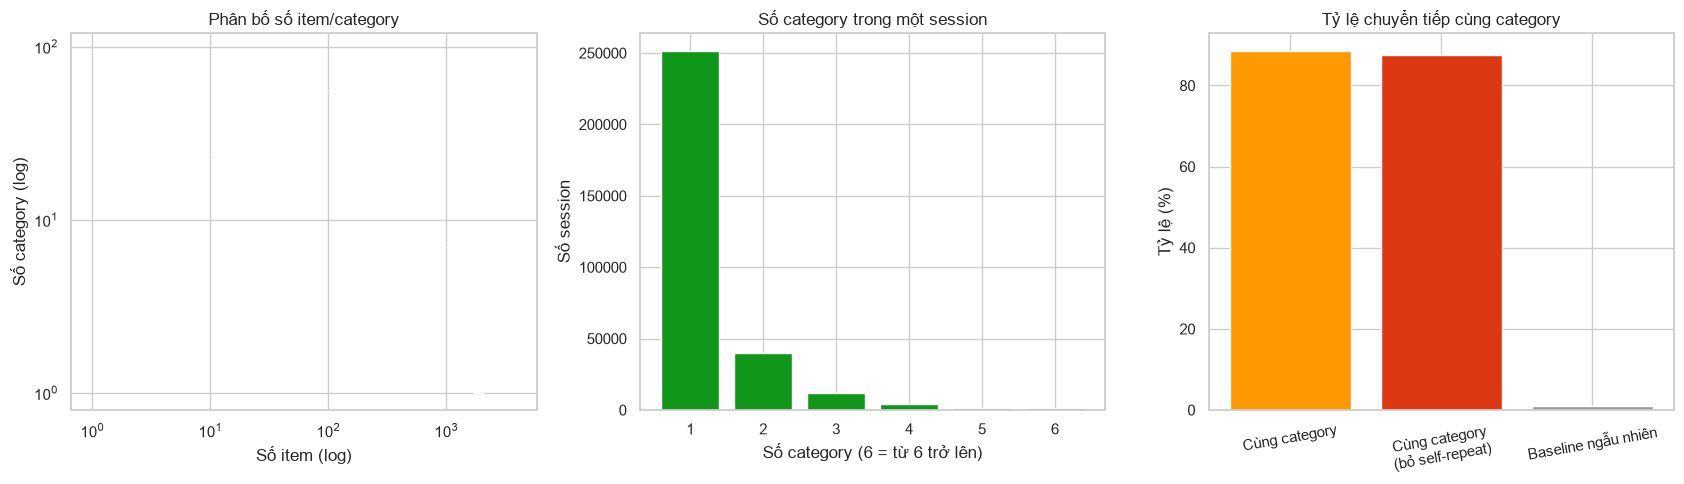

In [9]:
category_catalog = categories.groupby("categoryId").agg(
    catalog_items=("itemId", "nunique")
)
category_activity = events_with_category.groupby("categoryId").agg(
    active_items=("itemId", "nunique"),
    interactions=("itemId", "size"),
    sessions=("sessionId", "nunique"),
)
category_stats = category_catalog.join(category_activity, how="left").fillna(0)

previous_session = events_with_category["sessionId"].shift()
previous_item = events_with_category["itemId"].shift()
previous_category = events_with_category["categoryId"].shift()
is_transition = events_with_category["sessionId"].eq(previous_session)
is_non_self_transition = is_transition & events_with_category["itemId"].ne(previous_item)
is_same_category = events_with_category["categoryId"].eq(previous_category)
same_category_rate = float(
    (is_transition & is_same_category).sum() / is_transition.sum()
)
same_category_non_self_rate = float(
    (is_non_self_transition & is_same_category).sum()
    / is_non_self_transition.sum()
)
category_probability = events_with_category["categoryId"].value_counts(normalize=True)
independent_baseline = float((category_probability ** 2).sum())

category_summary = pd.DataFrame([
    ("number_of_categories", int(categories["categoryId"].nunique())),
    ("singleton_categories", int(category_stats["catalog_items"].eq(1).sum())),
    ("single_category_sessions", int(session_stats["unique_categories"].eq(1).sum())),
    ("single_category_sessions_pct", float(session_stats["unique_categories"].eq(1).mean() * 100)),
    ("same_category_transition_rate_pct", same_category_rate * 100),
    ("same_category_non_self_rate_pct", same_category_non_self_rate * 100),
    ("independent_random_baseline_pct", independent_baseline * 100),
], columns=["metric", "value"])

category_stats.reset_index().to_csv(
    TABLE_DIR / "eda_category_statistics.csv", index=False
)
category_summary.to_csv(TABLE_DIR / "eda_category_summary.csv", index=False)
display(category_stats.describe().T)
display(category_summary)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.histplot(
    category_stats["catalog_items"],
    bins=40,
    log_scale=(True, True),
    ax=axes[0],
    color="#3366cc",
)
axes[0].set(
    title="Phân bố số item/category",
    xlabel="Số item (log)",
    ylabel="Số category (log)",
)
category_count_plot = (
    session_stats["unique_categories"].clip(upper=6).value_counts().sort_index()
)
axes[1].bar(
    category_count_plot.index.astype(str),
    category_count_plot.values,
    color="#109618",
)
axes[1].set(
    title="Số category trong một session",
    xlabel="Số category (6 = từ 6 trở lên)",
    ylabel="Số session",
)
rate_names = ["Cùng category", "Cùng category\n(bỏ self-repeat)", "Baseline ngẫu nhiên"]
rate_values = [
    same_category_rate * 100,
    same_category_non_self_rate * 100,
    independent_baseline * 100,
]
axes[2].bar(
    rate_names,
    rate_values,
    color=["#ff9900", "#dc3912", "#999999"],
)
axes[2].set(title="Tỷ lệ chuyển tiếp cùng category", ylabel="Tỷ lệ (%)")
axes[2].tick_params(axis="x", rotation=10)
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "eda_category_structure_and_transition.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## 9. Mô phỏng pipeline lọc và phân bố target

Pipeline tham chiếu NARM/SR-GNN được mô phỏng theo đúng một lượt:

`session length ≥ 2 → item support ≥ 5 → session length ≥ 2`

Kết quả fixed-point chỉ dùng để đo độ nhạy, không được chọn tự động làm pipeline chính. Không có file processed nào được ghi ở đây.

In [10]:
def dataset_stage_stats(stage: str, frame: pd.DataFrame) -> dict:
    return {
        "stage": stage,
        "events": len(frame),
        "sessions": int(frame["sessionId"].nunique()),
        "items": int(frame["itemId"].nunique()),
        "categories": int(frame["categoryId"].nunique()),
        "prefix_target_examples": int(
            (frame.groupby("sessionId").size() - 1).clip(lower=0).sum()
        ),
    }


filter_stage_rows = [dataset_stage_stats("raw", events_with_category)]

lengths = events_with_category.groupby("sessionId").size()
stage_session = events_with_category[
    events_with_category["sessionId"].isin(lengths[lengths >= 2].index)
].copy()
filter_stage_rows.append(dataset_stage_stats("session_length_ge_2", stage_session))

support = stage_session["itemId"].value_counts()
stage_item = stage_session[
    stage_session["itemId"].isin(support[support >= 5].index)
].copy()
filter_stage_rows.append(dataset_stage_stats("then_item_support_ge_5", stage_item))

lengths = stage_item.groupby("sessionId").size()
standard_filtered = stage_item[
    stage_item["sessionId"].isin(lengths[lengths >= 2].index)
].copy()
filter_stage_rows.append(
    dataset_stage_stats("then_session_length_ge_2_again", standard_filtered)
)

fixed_point = events_with_category.copy()
previous_shape = None
fixed_point_iterations = 0
while previous_shape != (
    len(fixed_point),
    fixed_point["sessionId"].nunique(),
    fixed_point["itemId"].nunique(),
):
    previous_shape = (
        len(fixed_point),
        fixed_point["sessionId"].nunique(),
        fixed_point["itemId"].nunique(),
    )
    lengths = fixed_point.groupby("sessionId").size()
    fixed_point = fixed_point[
        fixed_point["sessionId"].isin(lengths[lengths >= 2].index)
    ]
    support = fixed_point["itemId"].value_counts()
    fixed_point = fixed_point[
        fixed_point["itemId"].isin(support[support >= 5].index)
    ]
    fixed_point_iterations += 1

filter_stage_rows.append(
    dataset_stage_stats(
        f"fixed_point_sensitivity_{fixed_point_iterations}_iterations",
        fixed_point,
    )
)

attrition = pd.DataFrame(filter_stage_rows)
for column in [
    "events",
    "sessions",
    "items",
    "categories",
    "prefix_target_examples",
]:
    attrition[f"{column}_retained_pct"] = (
        attrition[column] / attrition.loc[0, column] * 100
    )

standard_filtered["position"] = standard_filtered.groupby("sessionId").cumcount()
interaction_frequency_filtered = standard_filtered["itemId"].value_counts().rename(
    "interaction_frequency"
)
target_frequency = standard_filtered.loc[
    standard_filtered["position"] > 0, "itemId"
].value_counts().rename("target_frequency")
target_diagnostic = pd.concat(
    [interaction_frequency_filtered, target_frequency], axis=1
).fillna(0).astype(int)
target_frequency_spearman = spearmanr(
    target_diagnostic["interaction_frequency"],
    target_diagnostic["target_frequency"],
).statistic
items_never_target = int(target_diagnostic["target_frequency"].eq(0).sum())

filtered_lengths = standard_filtered.groupby("sessionId").size().rename(
    "session_length"
).to_frame()
filtered_lengths["length_group"] = pd.cut(
    filtered_lengths["session_length"],
    bins=[1, 5, 10, np.inf],
    labels=["2–5", "6–10", ">10"],
    include_lowest=True,
)
filtered_lengths["examples"] = filtered_lengths["session_length"] - 1
example_contribution = filtered_lengths.groupby(
    "length_group", observed=False
).agg(
    sessions=("session_length", "size"),
    prefix_target_examples=("examples", "sum"),
).reset_index()
example_contribution["example_share_pct"] = (
    example_contribution["prefix_target_examples"]
    / example_contribution["prefix_target_examples"].sum()
    * 100
)

attrition.to_csv(TABLE_DIR / "eda_preprocessing_attrition.csv", index=False)
target_diagnostic.reset_index(names="itemId").to_csv(
    TABLE_DIR / "eda_target_frequency_diagnostic.csv", index=False
)
example_contribution.to_csv(
    TABLE_DIR / "eda_prefix_target_contribution.csv", index=False
)

display(attrition)
print(
    "Spearman(interaction frequency, target frequency) "
    f"sau pipeline tham chiếu = {target_frequency_spearman:.4f}"
)
print(f"Số item chưa từng làm target = {items_never_target:,}")
display(example_contribution)

,stage,events,sessions,items,categories,prefix_target_examples,events_retained_pct,sessions_retained_pct,items_retained_pct,categories_retained_pct,prefix_target_examples_retained_pct
0,raw,1235380,310324,122993,1208,925056,100.0000,100.0000,100.0000,100.0000,100.0000
1,session_length_ge_2,1144686,219630,121468,1201,925056,92.6586,70.7744,98.7601,99.4205,100.0000
2,then_item_support_ge_5,1004834,216140,43136,995,788694,81.3380,69.6498,35.0719,82.3675,85.2591
3,then_session_length_ge_2_again,993483,204789,43136,995,788694,80.4192,65.9920,35.0719,82.3675,85.2591
4,fixed_point_sensitivity_6_iterations,989204,204061,42171,974,785143,80.0729,65.7574,34.2873,80.6291,84.8752


Spearman(interaction frequency, target frequency) sau pipeline tham chiếu = 0.9709
Số item chưa từng làm target = 8


,length_group,sessions,prefix_target_examples,example_share_pct
0,2–5,145365,300702,38.1266
1,6–10,44517,286307,36.3014
2,>10,14907,201685,25.5720


### 9.1. Độ nhạy của ngưỡng hỗ trợ item

Cùng một fixed-point pipeline được chạy với `minimum item frequency ∈ {1, 2, 3, 5, 10}`. Ngưỡng 1 là mốc không lọc item theo support nhưng vẫn loại session không thể tạo target. `raw_tail` trong bảng được định nghĩa cố định là item xuất hiện dưới 5 lần trong raw, để so sánh mức bảo toàn cùng một phần đuôi.

Phân tích này chỉ giúp định lượng trade-off và chọn ứng viên. Popularity chính thức vẫn phải tính từ train sau khi chia tập; EDA không tự động tuyên bố ngưỡng tối ưu từ raw.


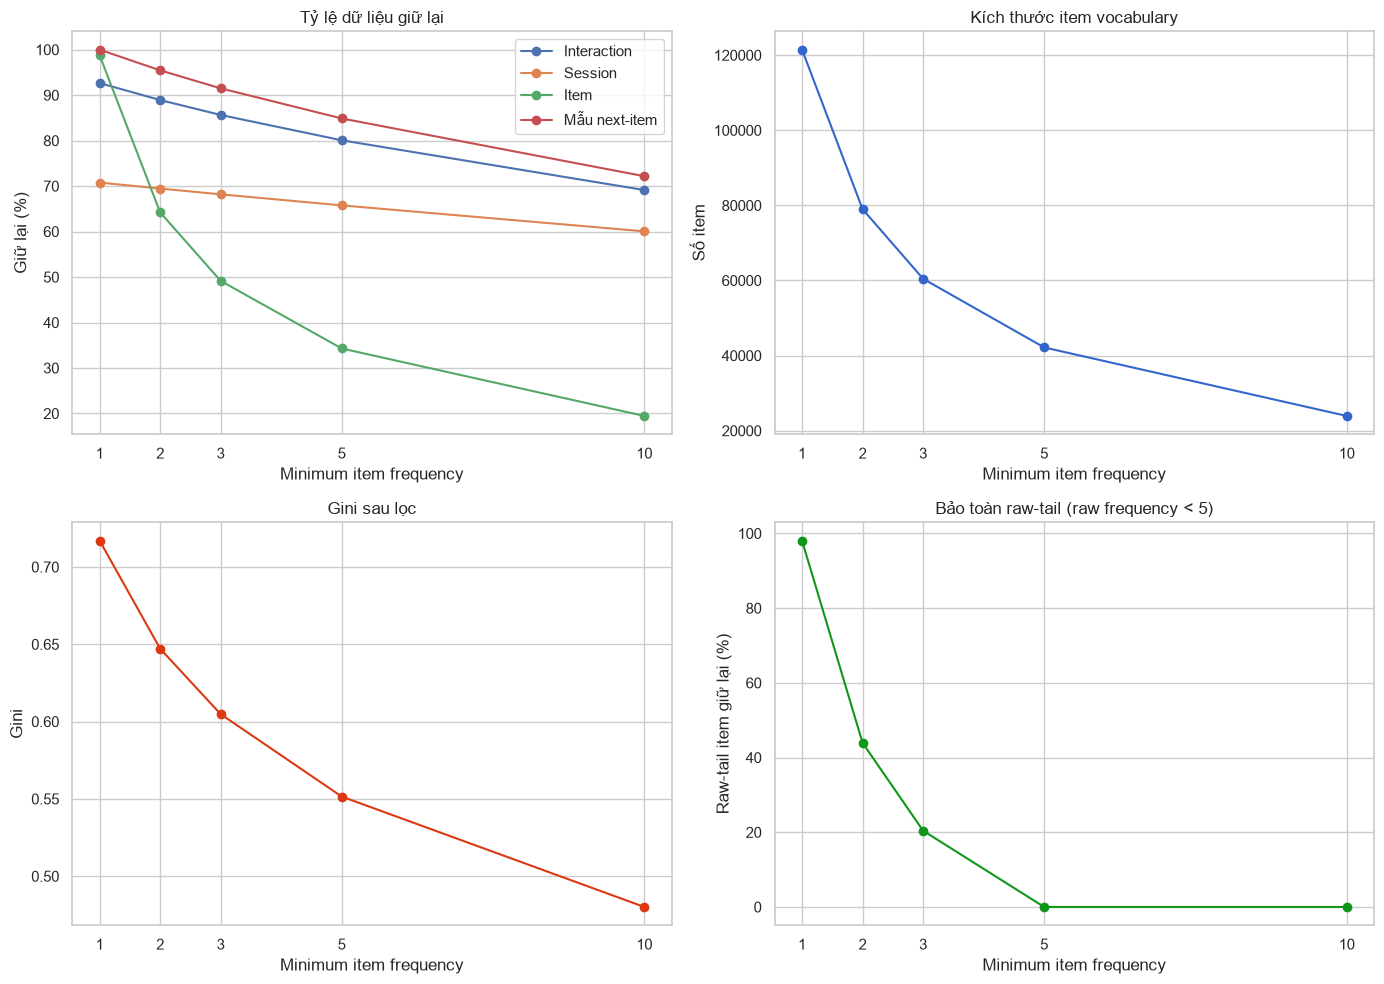

,min_item_frequency,iterations_to_converge,events,sessions,items,categories,prefix_target_examples,events_retained_pct,sessions_retained_pct,items_retained_pct,examples_retained_pct,raw_tail_items_retained,raw_tail_items_retained_pct,post_filter_gini,item_frequency_min,item_frequency_median,item_frequency_p90,item_frequency_max,embedding_table_64d_mib
0,1,2,1144686,219630,121468,1201,925056,92.6586,70.7744,98.7601,100.0000,76939,98.0564,0.7170,1,3.0000,21.0000,995,29.6553
1,2,5,1098507,215544,78989,1142,882963,88.9206,69.4577,64.2224,95.4497,34469,43.9297,0.6471,2,5.0000,31.0000,994,19.2844
2,3,6,1057976,211595,60454,1088,846381,85.6397,68.1852,49.1524,91.4951,16018,20.4145,0.6048,3,7.0000,38.0000,992,14.7593
3,5,6,989204,204061,42171,974,785143,80.0729,65.7574,34.2873,84.8752,0,0.0000,0.5515,5,12.0000,50.0000,985,10.2957
4,10,8,853942,186341,23920,770,667601,69.1238,60.0472,19.4483,72.1687,0,0.0000,0.4801,10,20.0000,72.0000,978,5.8398


,min_item_frequency,frequency_band,items,interactions,item_share_pct,interaction_share_pct
0,1,1,42035,42035,34.6058,3.6722
1,1,2–4,36297,97817,29.8819,8.5453
2,1,5,5270,26350,4.3386,2.3019
3,1,6–10,14747,112320,12.1406,9.8123
4,1,11–20,10799,158904,8.8904,13.8819
5,1,21–50,8165,257292,6.7219,22.4771
6,1,51–100,2735,189586,2.2516,16.5623
7,1,>100,1420,260382,1.1690,22.7470
8,2,1,0,0,0.0000,0.0000
9,2,2–4,36028,97116,45.6114,8.8407


Ngưỡng 5 vẫn là cấu hình tham chiếu; ngưỡng chính thức chỉ chốt sau khi đối chiếu trade-off và pilot training.


In [11]:
def fixed_point_filter(
    frame: pd.DataFrame,
    min_item_frequency: int,
    min_session_length: int = 2,
    max_iterations: int = 100,
) -> tuple[pd.DataFrame, int]:
    filtered = frame.copy()
    iterations = 0

    while iterations < max_iterations:
        before = (
            len(filtered),
            filtered["sessionId"].nunique(),
            filtered["itemId"].nunique(),
        )

        session_sizes = filtered.groupby("sessionId").size()
        filtered = filtered[
            filtered["sessionId"].isin(
                session_sizes[session_sizes >= min_session_length].index
            )
        ]

        item_counts = filtered["itemId"].value_counts()
        filtered = filtered[
            filtered["itemId"].isin(
                item_counts[item_counts >= min_item_frequency].index
            )
        ]
        iterations += 1

        after = (
            len(filtered),
            filtered["sessionId"].nunique(),
            filtered["itemId"].nunique(),
        )
        if after == before:
            break
    else:
        raise RuntimeError("Fixed-point filtering không hội tụ sau 100 vòng.")

    return filtered.copy(), iterations


thresholds = [1, 2, 3, 5, 10]
raw_counts = events_with_category["itemId"].value_counts()
raw_tail_items = pd.Index(raw_counts[raw_counts < 5].index)
raw_totals = dataset_stage_stats("raw", events_with_category)

threshold_rows = []
threshold_band_rows = []
threshold_frames = {}

for threshold in thresholds:
    filtered_frame, iterations = fixed_point_filter(
        events_with_category,
        min_item_frequency=threshold,
    )
    threshold_frames[threshold] = filtered_frame
    stats = dataset_stage_stats(f"min_item_frequency_{threshold}", filtered_frame)
    counts = filtered_frame["itemId"].value_counts()
    retained_items = pd.Index(counts.index)
    raw_tail_retained = raw_tail_items.intersection(retained_items)

    threshold_rows.append({
        "min_item_frequency": threshold,
        "iterations_to_converge": iterations,
        **{key: stats[key] for key in [
            "events", "sessions", "items", "categories", "prefix_target_examples"
        ]},
        "events_retained_pct": stats["events"] / raw_totals["events"] * 100,
        "sessions_retained_pct": stats["sessions"] / raw_totals["sessions"] * 100,
        "items_retained_pct": stats["items"] / raw_totals["items"] * 100,
        "examples_retained_pct": (
            stats["prefix_target_examples"]
            / raw_totals["prefix_target_examples"] * 100
        ),
        "raw_tail_items_retained": len(raw_tail_retained),
        "raw_tail_items_retained_pct": (
            len(raw_tail_retained) / len(raw_tail_items) * 100
        ),
        "post_filter_gini": gini_coefficient(counts),
        "item_frequency_min": int(counts.min()),
        "item_frequency_median": float(counts.median()),
        "item_frequency_p90": float(counts.quantile(0.90)),
        "item_frequency_max": int(counts.max()),
        "embedding_table_64d_mib": stats["items"] * 64 * 4 / (1024 ** 2),
    })

    bands = pd.cut(
        counts,
        bins=[0, 1, 4, 5, 10, 20, 50, 100, np.inf],
        labels=["1", "2–4", "5", "6–10", "11–20", "21–50", "51–100", ">100"],
    )
    band_summary = counts.groupby(bands, observed=False).agg(
        items="size", interactions="sum"
    ).reset_index(names="frequency_band")
    band_summary.insert(0, "min_item_frequency", threshold)
    band_summary["item_share_pct"] = band_summary["items"] / len(counts) * 100
    band_summary["interaction_share_pct"] = (
        band_summary["interactions"] / counts.sum() * 100
    )
    threshold_band_rows.append(band_summary)

threshold_sensitivity = pd.DataFrame(threshold_rows)
threshold_frequency_bands = pd.concat(threshold_band_rows, ignore_index=True)

threshold_sensitivity.to_csv(
    TABLE_DIR / "eda_frequency_threshold_sensitivity.csv", index=False
)
threshold_frequency_bands.to_csv(
    TABLE_DIR / "eda_threshold_frequency_bands.csv", index=False
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for column, label in [
    ("events_retained_pct", "Interaction"),
    ("sessions_retained_pct", "Session"),
    ("items_retained_pct", "Item"),
    ("examples_retained_pct", "Mẫu next-item"),
]:
    axes[0, 0].plot(
        threshold_sensitivity["min_item_frequency"],
        threshold_sensitivity[column], marker="o", label=label,
    )
axes[0, 0].set(
    title="Tỷ lệ dữ liệu giữ lại",
    xlabel="Minimum item frequency", ylabel="Giữ lại (%)",
    xticks=thresholds,
)
axes[0, 0].legend()

axes[0, 1].plot(
    threshold_sensitivity["min_item_frequency"],
    threshold_sensitivity["items"], marker="o", color="#3366cc",
)
axes[0, 1].set(
    title="Kích thước item vocabulary",
    xlabel="Minimum item frequency", ylabel="Số item",
    xticks=thresholds,
)

axes[1, 0].plot(
    threshold_sensitivity["min_item_frequency"],
    threshold_sensitivity["post_filter_gini"], marker="o", color="#dc3912",
)
axes[1, 0].set(
    title="Gini sau lọc",
    xlabel="Minimum item frequency", ylabel="Gini",
    xticks=thresholds,
)

axes[1, 1].plot(
    threshold_sensitivity["min_item_frequency"],
    threshold_sensitivity["raw_tail_items_retained_pct"],
    marker="o", color="#109618",
)
axes[1, 1].set(
    title="Bảo toàn raw-tail (raw frequency < 5)",
    xlabel="Minimum item frequency", ylabel="Raw-tail item giữ lại (%)",
    xticks=thresholds,
)
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "eda_frequency_threshold_tradeoff.png",
    dpi=180, bbox_inches="tight",
)
plt.show()

display(threshold_sensitivity)
display(threshold_frequency_bands)
print(
    "Ngưỡng 5 vẫn là cấu hình tham chiếu; "
    "ngưỡng chính thức chỉ chốt sau khi đối chiếu trade-off và pilot training."
)


## 10. Kết luận EDA và bàn giao sang preprocessing

Cell cuối tổng hợp những kết luận có thể kiểm tra tự động. Các quyết định về split, cold-start 20% và popularity group chỉ được thực hiện trong notebook `02_preprocessing.ipynb` sau khi giao thức Mục 1.6 được xác nhận.

In [12]:
conclusions = pd.DataFrame([
    {
        "question": "Ba file có liên kết đầy đủ cho item đã tương tác?",
        "result": (
            int((~view_items.isin(category_items)).sum()) == 0
            and int((~view_items.isin(product_items)).sum()) == 0
        ),
        "evidence": "missing category=0, missing product=0",
    },
    {
        "question": "Cần sắp xếp lại chuỗi theo timeframe?",
        "result": sessions_out_of_order > 0,
        "evidence": f"{sessions_out_of_order:,} session không tăng timeframe trong thứ tự raw",
    },
    {
        "question": "Session length 1 có đáng kể?",
        "result": session_stats["session_length"].eq(1).mean() > 0.01,
        "evidence": f"{session_stats['session_length'].eq(1).mean() * 100:.2f}% session",
    },
    {
        "question": "Click lặp có đáng kể?",
        "result": all_repeat_events > 0,
        "evidence": f"{all_repeat_events / len(events) * 100:.2f}% event là lượt lặp trong session",
    },
    {
        "question": "Dữ liệu có long tail rõ?",
        "result": (interaction_frequency < 5).mean() > 0.5,
        "evidence": (
            f"{(interaction_frequency < 5).mean() * 100:.2f}% item xuất hiện dưới 5 lần; "
            f"Gini={input_gini:.3f}"
        ),
    },
    {
        "question": "Category phản ánh cấu trúc session?",
        "result": same_category_non_self_rate > independent_baseline,
        "evidence": (
            f"same-category non-self={same_category_non_self_rate * 100:.2f}% "
            f"so với baseline={independent_baseline * 100:.2f}%"
        ),
    },
    {
        "question": "Item age có thể gây nhiễu popularity?",
        "result": abs(age_frequency_spearman) >= 0.1,
        "evidence": f"Spearman frequency-age={age_frequency_spearman:.3f}",
    },
    {
        "question": "Session nhiều ngày đều dưới 30 phút?",
        "result": bool(multi_day_detail["duration_seconds"].lt(30 * 60).all()),
        "evidence": (
            f"{len(multi_day_ids):,} session qua hai ngày liên tiếp; "
            f"duration max theo timeframe={session_calendar['duration_seconds'].max():.2f}s"
        ),
    },
    {
        "question": "Ngưỡng item support có trade-off lớn?",
        "result": (
            threshold_sensitivity["items_retained_pct"].max()
            - threshold_sensitivity["items_retained_pct"].min()
        ) > 10,
        "evidence": (
            f"item giữ lại: threshold 1={threshold_sensitivity.iloc[0]['items_retained_pct']:.2f}%; "
            f"threshold 10={threshold_sensitivity.iloc[-1]['items_retained_pct']:.2f}%"
        ),
    },
    {
        "question": "Fixed-point filtering có làm đổi catalog?",
        "result": standard_filtered["itemId"].nunique() != fixed_point["itemId"].nunique(),
        "evidence": (
            f"one-pass={standard_filtered['itemId'].nunique():,} item; "
            f"fixed-point={fixed_point['itemId'].nunique():,} item"
        ),
    },
])

conclusions.to_csv(TABLE_DIR / "eda_conclusions.csv", index=False)
display(conclusions)

print("Các bước tiếp theo trong 02_preprocessing.ipynb:")
print("1. Chốt chính xác giao thức cold-start 20% từ Mục 1.6 / Option B.")
print("2. Dùng ngưỡng 5 làm tham chiếu; đối chiếu ngưỡng 2/3 trong pilot nếu tài nguyên cho phép.")
print("3. Áp dụng pipeline lọc đã chọn và lưu attrition chính thức.")
print("4. Chia train/validation/test theo ngày cuối của session, không tách session qua nửa đêm.")
print("5. Tính popularity chỉ từ train; kiểm tra ties trước khi chia group.")
print("6. Audit leakage, candidate catalog, cold/warm item và số mẫu đánh giá từng group.")
print(f"\nĐã lưu bảng vào: {TABLE_DIR}")
print(f"Đã lưu hình vào: {FIGURE_DIR}")

,question,result,evidence
0,Ba file có liên kết đầy đủ cho item đã tương tác?,True,"missing category=0, missing product=0"
1,Cần sắp xếp lại chuỗi theo timeframe?,True,"180,643 session không tăng timeframe trong thứ..."
2,Session length 1 có đáng kể?,True,29.23% session
3,Click lặp có đáng kể?,True,13.62% event là lượt lặp trong session
4,Dữ liệu có long tail rõ?,True,63.80% item xuất hiện dưới 5 lần; Gini=0.726
5,Category phản ánh cấu trúc session?,True,same-category non-self=87.45% so với baseline=...
6,Item age có thể gây nhiễu popularity?,True,Spearman frequency-age=0.504
7,Session nhiều ngày đều dưới 30 phút?,True,260 session qua hai ngày liên tiếp; duration m...
8,Ngưỡng item support có trade-off lớn?,True,item giữ lại: threshold 1=98.76%; threshold 10...
9,Fixed-point filtering có làm đổi catalog?,True,"one-pass=43,136 item; fixed-point=42,171 item"


Các bước tiếp theo trong 02_preprocessing.ipynb:
1. Chốt chính xác giao thức cold-start 20% từ Mục 1.6 / Option B.
2. Dùng ngưỡng 5 làm tham chiếu; đối chiếu ngưỡng 2/3 trong pilot nếu tài nguyên cho phép.
3. Áp dụng pipeline lọc đã chọn và lưu attrition chính thức.
4. Chia train/validation/test theo ngày cuối của session, không tách session qua nửa đêm.
5. Tính popularity chỉ từ train; kiểm tra ties trước khi chia group.
6. Audit leakage, candidate catalog, cold/warm item và số mẫu đánh giá từng group.

Đã lưu bảng vào: D:\DA-3\results\tables
Đã lưu hình vào: D:\DA-3\results\figures
